**Large Language Models**

_Copyright Notice_

This notebook is available for educational purposes. You may not use or distribute this notebook for commercial purposes. You may make copies of this notebook and use or distribute it for educational purposes as long as you cite the author as the source of the notebook.

Jaeyoung Chun | School of Applied Artificial Intelligence | Handong Global University

# Simple Graph - Chatbot

## Load Environment Variables

In [1]:
from dotenv import load_dotenv

In [2]:
# retrieve API key and other environment variables
load_dotenv()

True

## Define State

In [3]:
from typing import TypedDict

In [4]:
class State(TypedDict):
    number: int

## Define Node

### Model

In [5]:
from langchain_openai import ChatOpenAI

In [6]:
model = ChatOpenAI(
    model_name="gpt-6-luna"
)

### Prompt

In [7]:
from langchain_core.prompts import ChatPromptTemplate

In [8]:
prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system", "You are a helpful assistant.",
        ),
        (
            "human", "Substract 1 from {number}. Return only the final outcome."
        )
    ]
)

### Chain

In [9]:
from langchain_core.output_parsers import StrOutputParser

In [10]:
chain = prompt | model | StrOutputParser()

### Node

In [11]:
def chatbot(state: State):

    old_number = state["number"]
    
    out = chain.invoke(
        {
            "number": old_number
        
        }
    )

    new_number = int(out)

    return {
        "number": new_number
    }

## Build Graph

In [12]:
from langgraph.graph import StateGraph, START, END

In [13]:
# different way to bulid and compile graph
graph = (
    StateGraph(State)
    .add_node("chatbot", chatbot)
    .add_edge(START, "chatbot")
    .add_edge("chatbot", END)
    .compile()
)

## Visualize Graph

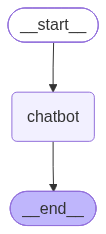

In [14]:
from IPython.display import Image, display

diagram = Image(graph.get_graph().draw_mermaid_png())
    
display(diagram)

## Invoke

In [15]:
out = graph.invoke(
    {
        "number": 13
    }   
)

In [16]:
out

{'number': 12}